In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const

from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [10]:
data, var = load_data_and_var()

/Users/eleanorstuart/Desktop/krisp/thermo-idm/load_data_and_var.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX'][['OName',


In [11]:
nfws_full=generate_nfws_from_combined_dataset_werr(data, var)

In [12]:
nfws = [nfw for nfw in nfws_full if nfw.z < 0.2]

In [5]:
nfws_subset = [nfw for nfw in nfws if nfw.energies.is_virialized_gaspari ]
zs = [nfw.z for nfw in nfws_subset]
filtered_vir = [nfw.energies.virialization_fraction_gaspari for nfw in nfws_subset]

len(nfws_subset)

111

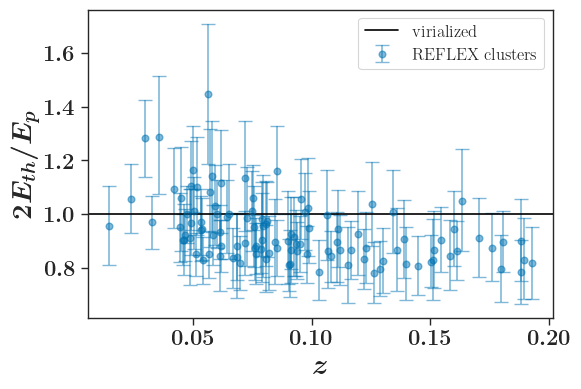

In [6]:
paper_plot()
fig = plt.figure()
plt.errorbar(zs, filtered_vir,
             yerr=[[v.minus for v in filtered_vir],[v.plus for v in filtered_vir]], 
             fmt='o', capsize=5, capthick=1, alpha=0.5, label='REFLEX clusters')
plt.axhline(1.0, color='black', label='virialized')

plt.xlabel(f'$z$')
plt.ylabel(f'$2E_{{th}}/E_{{p}}$')
plt.legend()

In [53]:
#savefig(fig,'plots/virialization.png') 

2024-07-18T09:38:39.238567: made plots/virialization.png


In [13]:
heating_rates = np.array([nfw.total_heating_rate(0.001*nfw.R500, nfw.R500, 0.1*nfw.R500) for nfw in nfws_subset])

In [14]:
cooling_rates = np.array([nfw.total_cooling_rate(0.001*nfw.R500, nfw.R500, vol_rate='gfe') for nfw in nfws_subset])

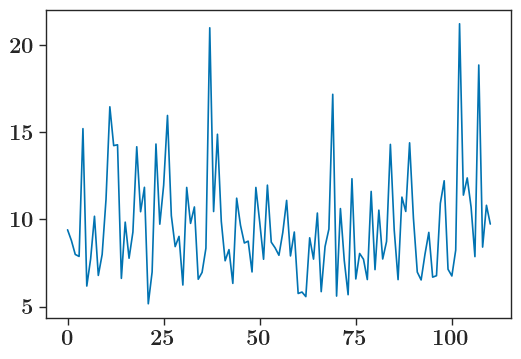

In [21]:
plt.plot(np.divide(heating_rates, cooling_rates))

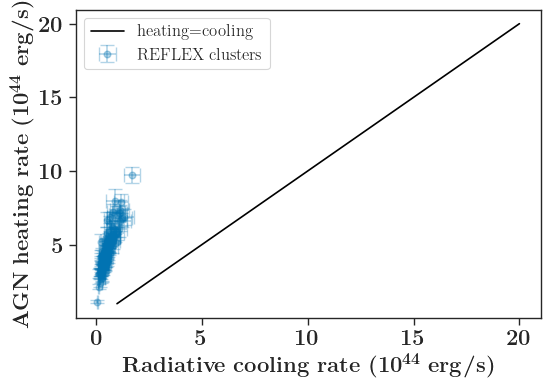

In [15]:
fig2 = plt.figure()
plt.errorbar(cooling_rates/1e44, heating_rates/1e44,
             xerr=[[c.minus for c in cooling_rates/1e44],[c.plus for c in cooling_rates/1e44]],
             yerr=[[h.minus for h in heating_rates/1e44],[h.plus for h in heating_rates/1e44]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='REFLEX clusters')

plt.plot([1, 20], [1, 20], label='heating=cooling', c='k')
plt.ylabel(f'$\mathrm{{AGN~heating~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.xlabel(f'$\mathrm{{Radiative~cooling~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.legend()

In [89]:
#savefig(fig2,'plots/heating_cooling.png') 

2024-07-18T11:48:45.560724: made plots/heating_cooling.png


[]

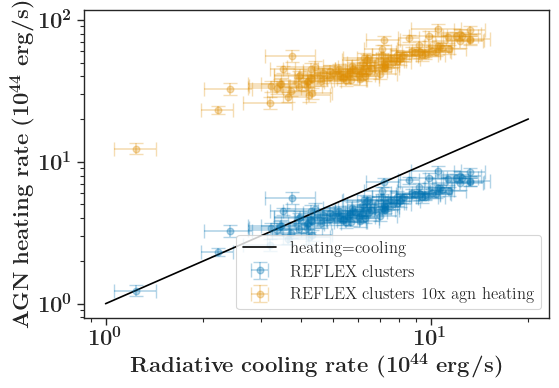

In [86]:
plt.errorbar(cooling_rates/1e44, heating_rates/1e44,
             xerr=[[c.minus for c in cooling_rates/1e44],[c.plus for c in cooling_rates/1e44]],
             yerr=[[h.minus for h in heating_rates/1e44],[h.plus for h in heating_rates/1e44]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='REFLEX clusters')

plt.errorbar(cooling_rates/1e44, 10*heating_rates/1e44,
             xerr=[[c.minus for c in cooling_rates/1e44],[c.plus for c in cooling_rates/1e44]],
             yerr=[[h.minus for h in 10*heating_rates/1e44],[h.plus for h in 10*heating_rates/1e44]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='REFLEX clusters 10x agn heating')

plt.plot([1, 20], [1, 20], label='heating=cooling', c='k')
plt.ylabel(f'$\mathrm{{AGN~heating~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.xlabel(f'$\mathrm{{Radiative~cooling~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.legend()
plt.loglog()

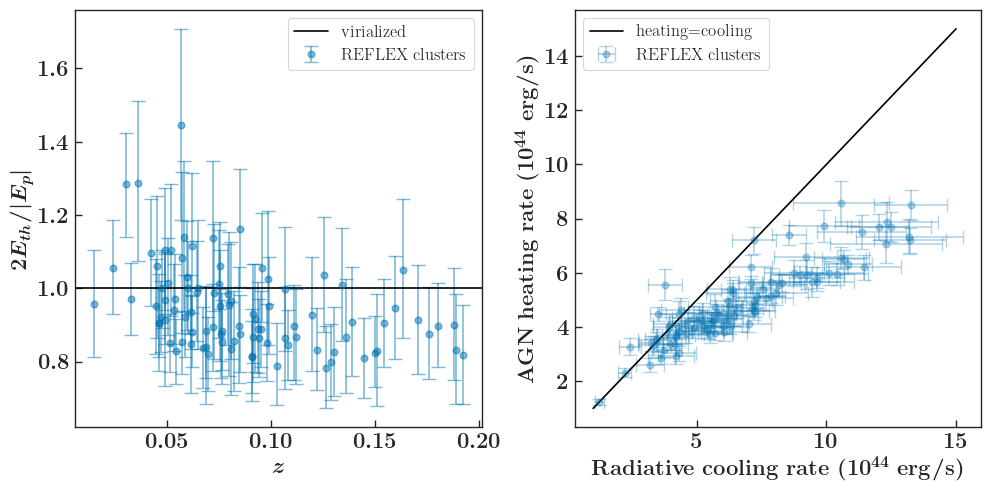

In [97]:
subplotsfig, (ax1, ax2) =  plt.subplots(1, 2, figsize=(10, 5))

# First subplot
ax1.errorbar(zs, filtered_vir,
             yerr=[[v.minus for v in filtered_vir],[v.plus for v in filtered_vir]], 
             fmt='o', capsize=5, capthick=1, alpha=0.5, label='REFLEX clusters')
ax1.axhline(1.0, color='black', label='virialized')
ax1.legend()
#ax1.set_title('Plot 1')
ax1.set_xlabel(f'$z$', size=16)
ax1.set_ylabel(f'$2E_{{th}}/|E_{{p}}|$', size=16)
ax1.tick_params(axis='y', direction='in')
ax1.tick_params(axis='x', direction='in')

# Second subplot
ax2.errorbar(cooling_rates/1e44, heating_rates/1e44,
             xerr=[[c.minus for c in cooling_rates/1e44],[c.plus for c in cooling_rates/1e44]],
             yerr=[[h.minus for h in heating_rates/1e44],[h.plus for h in heating_rates/1e44]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='REFLEX clusters')

ax2.plot([1, 15], [1, 15], label='heating=cooling', c='k')
ax2.set_ylabel(f'$\mathrm{{AGN~heating~rate~(10^{{44}}~erg/s)}}$', size=16)
ax2.set_xlabel(f'$\mathrm{{Radiative~cooling~rate~(10^{{44}}~erg/s)}}$', size=16)
ax2.legend()
ax2.tick_params(axis='y', direction='in')
ax2.tick_params(axis='x', direction='in')
#ax2.set_title('Plot 2')

plt.tight_layout()

In [98]:
#savefig(subplotsfig,'plots/equilibrium_plots.png') 

2024-07-22T11:02:07.595934: made plots/equilibrium_plots.png


In [17]:
import pickle
with open('data/mcxc_psz_combined.pkl', 'rb') as f:
        comb_data = pickle.load(f)

In [19]:
comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX']['L500']

/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_44310/616889684.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX']['L500']


2      0.846881
3      1.809494
6      1.086002
9      1.236332
10     2.827248
         ...   
541    1.852614
543    1.029501
547    1.336537
549    1.629622
550    1.051539
Name: L500, Length: 173, dtype: float64